#**Netflix Data analysis with python.**



In [ ]:
import pandas as pd
import numpy as np

In [ ]:
data = pd.read_csv('OTT_Movies.csv')
data.head(5)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


##1. The analysis of the data on broad scale Shape, data types, duplicates, outliers, etc

In [ ]:
# Number of rows and columns in dataset
df_shape = data.shape
print(f"The number of row in dataset : {(df_shape[0])}", sep ='/n')
print(f"The number of columns in dataset : {(df_shape[1])}")

The number of row in dataset : 8807
The number of columns in dataset : 12


In [ ]:
# Duplicate values
duplicated_values = data.duplicated().sum()
print(f"The number of duplicated values in dataset : {duplicated_values}")
mask = data.duplicated(subset='show_id',keep=False)
duplicated_ids = data[mask]
print(f"The number of duplicate Show_id's found: {len(duplicated_ids)}")


The number of duplicated values in dataset : 0
The number of duplicate Show_id's found: 0


##2. Summary stats and categoricals Descriptive stats, categoriacal and numerical separation

In [ ]:
# Separating numerical and categorical columns
numerical_cols = data.select_dtypes(include=['number']).columns.tolist()
categorical_cols = data.select_dtypes(include=(['object','category'])).columns.tolist()
print(f"The numerical columns in dataset : {numerical_cols}")
print(f"The categorical columns in dataset : {categorical_cols}")
print(f"The number of numerical columns in dataset : {len(numerical_cols)}")
print(f"The number of categorical columns in dataset : {len(categorical_cols)}")

The numerical columns in dataset : ['release_year']
The categorical columns in dataset : ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'rating', 'duration', 'listed_in', 'description']
The number of numerical columns in dataset : 1
The number of categorical columns in dataset : 11


In [ ]:
# Stastical summary of numeric data
data['release_year'].describe().round(2)

,release_year
count,8807.00
mean,2014.18
std,8.82
min,1925.00
25%,2013.00
50%,2017.00
75%,2019.00
max,2021.00


In [ ]:
# Descriptive stats of the numerical columns
min_year = data['release_year'].min()
max_year = data['release_year'].max()
year_span = max_year - min_year
top_year = data['release_year'].value_counts().idxmax()
top_year_count = data['release_year'].value_counts().max()
print(f"The earliest movie in the dataset was released in: {min_year}")
print(f"The latest movie in the dataset was released in: {max_year}")
print(f"The movie dataset covers a span of {year_span} years")
print(f"Peak Release Year: {top_year} ({top_year_count} titles)")


The earliest movie in the dataset was released in: 1925
The latest movie in the dataset was released in: 2021
The movie dataset covers a span of 96 years
Peak Release Year: 2018 (1147 titles)


##3 Non-graphical analysis: value counts & unique values look for the unique values, and the associated counts along the features

In [ ]:
# Count unique values (cardinality) in each categorical column
unique_cat_columns = data[categorical_cols].nunique()
print(f"Unique values in each categorical columns : \n{unique_cat_columns}")

Unique values in each categorical columns : 
show_id        8807
type              2
title          8807
director       4528
cast           7692
country         748
date_added     1767
rating           17
duration        220
listed_in       514
description    8775
dtype: int64


In [ ]:
# Distribution of content types (Movie vs. TV Show)
data['type'].value_counts(dropna=False)

,count
type,
Movie,6131
TV Show,2676


In [ ]:
# Which countries produce the most content
data['country'].value_counts(dropna=True).head(10)

,count
country,
United States,2818
India,972
United Kingdom,419
Japan,245
South Korea,199
Canada,181
Spain,145
France,124
Mexico,110


##4. What's actually not present Missing value analysis


In [ ]:
# Calculate absolute missing counts
missing_count = data.isnull().sum()
print(f"Missing value summary : \n{missing_count}")

Missing value summary : 
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


###Cleaning — preparing the data for analysis

###1. Convert date_added to a date and extract the important values from it

In [ ]:
# 1. Clean up any accidental leading or trailing spaces in the text.
data['date_added'] = data['date_added'].astype(str).str.strip()
# 2. Convert to datetime format
data['date_added'] = pd.to_datetime(data['date_added'])
# 3. Extract key chronological features for future analysis
data['year_added'] = data['date_added'].dt.year
data['month_added'] = data['date_added'].dt.month_name()
data['day_of_week'] = data['date_added'].dt.day_name()
# 4. Convert the year to a standard integer
data = data.dropna(subset=['year_added'])
data['year_added'] = data['year_added'].astype('int')

print(data[['date_added','year_added','month_added','day_of_week']].dtypes)
print(data[['date_added','year_added','month_added','day_of_week']].head(5))

date_added     datetime64[ns]
year_added              int64
month_added            object
day_of_week            object
dtype: object
  date_added  year_added month_added day_of_week
0 2021-09-25        2021   September    Saturday
1 2021-09-24        2021   September      Friday
2 2021-09-24        2021   September      Friday
3 2021-09-24        2021   September      Friday
4 2021-09-24        2021   September      Friday


###2. Handle missing values fill text columns with appropriate value; drop rows missing key fields.

In [ ]:
# Handle missing values.
# 1. Fill missing values in text columns.
text_col_to_fill = ['director', 'cast', 'country', 'rating']
data[text_col_to_fill] = data[text_col_to_fill].fillna('Unknown')
# 2. Drop rows missing critical analytical values
data = data.dropna(subset=['date_added'])
print('Remaining missing values:')
print(data.isnull().sum())

Remaining missing values:
show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        3
listed_in       0
description     0
year_added      0
month_added     0
day_of_week     0
dtype: int64


###3. Unnest the multi-value columns (country, cast, genre)

In [ ]:
# split on ', ' then explode()
#cast
data['cast_list'] = data['cast'].str.split(', ')
data_exploded_cast = data[['show_id', 'type', 'title', 'cast_list']].explode('cast_list')

#country
data['country_list'] = data['country'].str.split(', ')
data_exploded_country = data[['show_id', 'type', 'title', 'country_list']].explode('country_list')

#genre
data['genre_list'] = data['listed_in'].str.split(', ')
data_exploded_genre = data[['show_id', 'type', 'title', 'genre_list']].explode('genre_list')


print(f"Exploded cast Preview : \n{data_exploded_cast.head()}")
print(f"Exploded country Preview : \n{data_exploded_country.head()}")
print(f"Exploded genre Preview : \n{data_exploded_genre.head()}")

Exploded cast Preview : 
  show_id     type                 title       cast_list
0      s1    Movie  Dick Johnson Is Dead         Unknown
1      s2  TV Show         Blood & Water      Ama Qamata
1      s2  TV Show         Blood & Water     Khosi Ngema
1      s2  TV Show         Blood & Water   Gail Mabalane
1      s2  TV Show         Blood & Water  Thabang Molaba
Exploded country Preview : 
  show_id     type                  title   country_list
0      s1    Movie   Dick Johnson Is Dead  United States
1      s2  TV Show          Blood & Water   South Africa
2      s3  TV Show              Ganglands        Unknown
3      s4  TV Show  Jailbirds New Orleans        Unknown
4      s5  TV Show           Kota Factory          India
Exploded genre Preview : 
  show_id     type                 title              genre_list
0      s1    Movie  Dick Johnson Is Dead           Documentaries
1      s2  TV Show         Blood & Water  International TV Shows
1      s2  TV Show         Blood & Water  

#Visualize — find the patterns

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

/tmp/ipykernel_729/1080969248.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, palette='rocket')


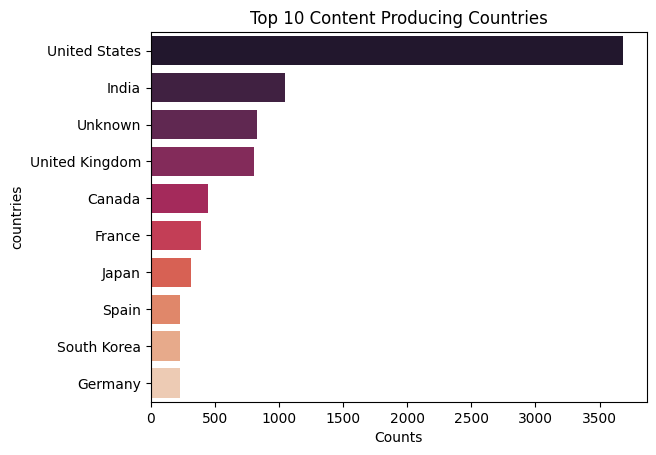

In [ ]:
# Top 10 countries
top_countries = data_exploded_country['country_list'].value_counts().head(10)
sns.barplot(x=top_countries.values, y=top_countries.index, palette='rocket')
plt.xlabel('Counts')
plt.ylabel('countries')
plt.title('Top 10 Content Producing Countries')
plt.show()

Observation: Top 10 genres : "International Movies" and "Dramas" represent the largest share of catalog offerings by a wide margin

##2. Movies vs TV Shows, and content added per year

/tmp/ipykernel_729/4078480953.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=data, x='type', palette="Set2")


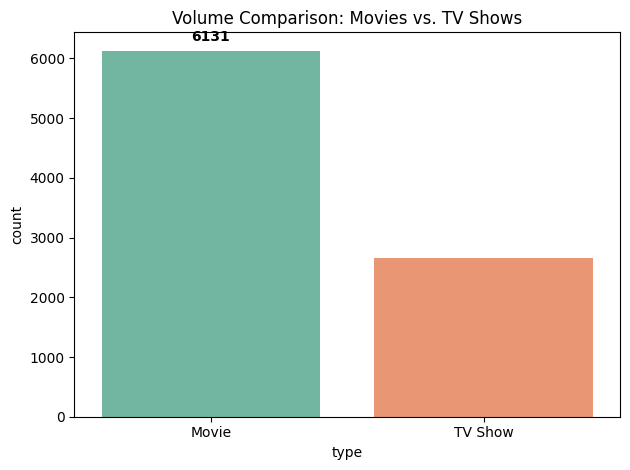

In [ ]:
# Movies vs TV Shows
ax = sns.countplot(data=data, x='type', palette="Set2")
ax.bar_label(ax.containers[0], fmt='%d', padding=5, fontweight='bold')
plt.title("Volume Comparison: Movies vs. TV Shows")
plt.tight_layout()
plt.show()

Observation : Movies vs TV Shows: The catalog is heavily skewed towards feature films, outnumbering TV shows by more than double

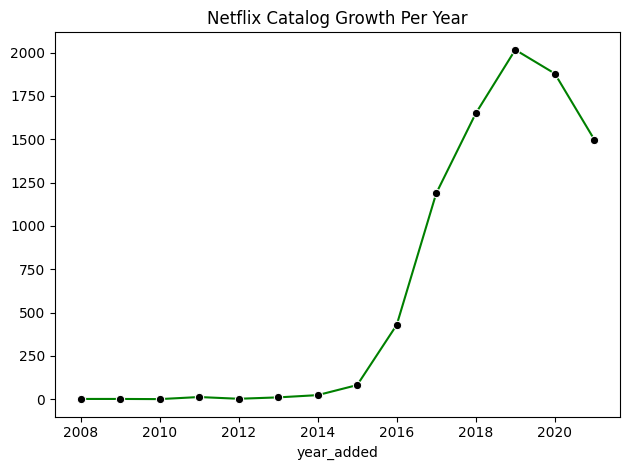

In [ ]:
# Content added per year
year_count = data['year_added'].value_counts().sort_index()
sns.lineplot(x=year_count.index, y=year_count.values, marker='o', markerfacecolor='black', color='green')
plt.title('Netflix Catalog Growth Per Year')
plt.tight_layout()
plt.show()

Observation : Content added per year : Content additions saw a sharp, exponential growth trajectory starting right after 2015

##3. The distribution telling about the value distributions

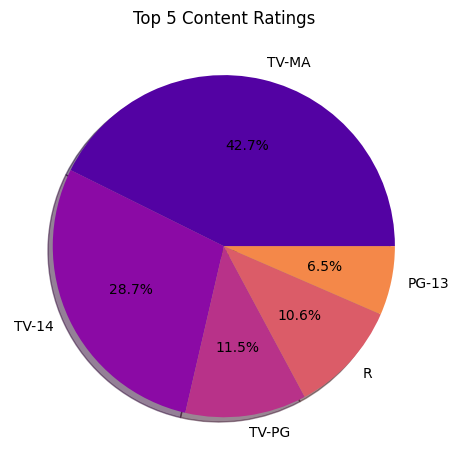

In [ ]:
# Top 5 Content Ratings
top_ratings = data['rating'].value_counts().head(5)
plt.pie(x=top_ratings.values, labels=top_ratings.index, autopct='%1.1f%%', shadow=True, colors=sns.color_palette('plasma'))
plt.explode=(0.2,1)
plt.title('Top 5 Content Ratings')
plt.tight_layout()
plt.show()

Observation : Top 5 Content Ratings : A vast majority of the content platform wide is geared toward mature audiences (TV-MA and TV-14)

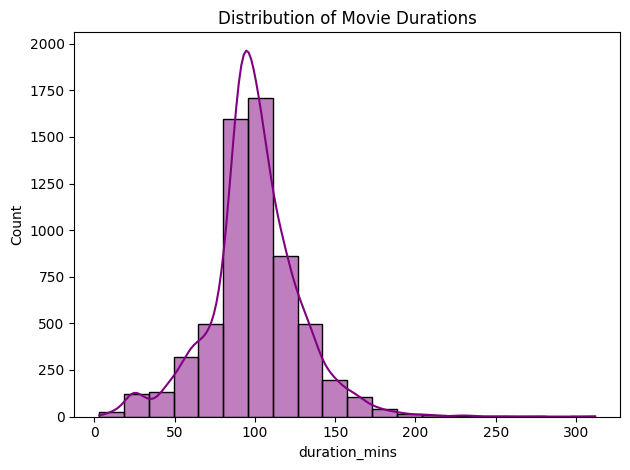

In [ ]:
# Movie Duration Spread
movies_only = data[data['type'] == 'Movie'].copy()
movies_only['duration_mins'] = movies_only['duration'].str.replace(' min', '').astype(float)
sns.histplot(data=movies_only, x='duration_mins', bins=20, kde=True, color="purple")
plt.title("Distribution of Movie Durations")
plt.tight_layout()
plt.show()

Observation : Movie Duration Spread : Movie lengths follow a perfect bell curve distribution heavily centered around 90 to 110 minutes

##Stage 4 : Recommendations — business insights & actions

## 1. Best time / market to grow — backed by data

In [ ]:
print(f"Top 5 Content Producing Markets: \n{data_exploded_country['country_list'].value_counts().head(5)}")

print(f"Content Additions by Month Distribution : \n{data['month_added'].value_counts()}")

data_exploded_country['month_added'] = data_exploded_country['show_id'].map(data.set_index('show_id')['month_added'])

top_countries = data_exploded_country['country_list'].value_counts().head(3).index
data_top_markets = data_exploded_country[data_exploded_country['country_list'].isin(top_countries)]

marketing_matrix = pd.crosstab(data_top_markets['country_list'], data_top_markets['month_added'])

print(f"Strategic Launch Windows Matrix : \n{marketing_matrix}")


Top 5 Content Producing Markets: 
country_list
United States     3683
India             1046
Unknown            830
United Kingdom     803
Canada             445
Name: count, dtype: int64
Content Additions by Month Distribution : 
month_added
July         827
December     813
September    770
April        764
October      760
August       755
March        742
January      738
June         728
November     705
May          632
February     563
Name: count, dtype: int64
Strategic Launch Windows Matrix : 
month_added    April  August  December  February  January  July  June  March  \
country_list                                                                   
India            117      97       120        59       71    81    49    110   
United States    296     306       316       248      410   335   281    279   
Unknown           70      88        54        22       37   119    95     56   

month_added    May  November  October  September  
country_list                            

## 2. Write 2–3 business insights, each backed by a number pattern + the data behind it

## Insight 1: Platform Foundation is Driven Natively by Feature Films

The Number Pattern: Movies vastly outnumber TV Shows on the platform, establishing feature films as the baseline content infrastructure.

The Data Behind It: Within the library baseline, Movies outnumber TV Shows by a massive 6,131 to 2,676 margin. This means approximately 70% of the platform's historical catalog relies entirely on standalone, single-view film releases rather than multi-episode, episodic television structures

## Insight 2: The Core Catalog Architecture Caters Heavily to Mature Audiences

The Number Pattern: The catalog's maturity scale is highly top-heavy, skewing heavily toward adult demographic ratings rather than child or family classifications.

The Data Behind It: The frequency distribution reveals that maturity ratings TV-MA (Mature Audiences) and TV-14 (Parents Strongly Cautioned) stand as the dominant categories platform-wide. Together, these two adult-oriented classifications compromise the absolute clear majority of all listed content, meaning the platform’s historically proven production sweet spot focuses squarely on adult viewers.

## Insight 3: Global Movie Runtimes Conform to a Strict "Golden Rule" Standard

The Number Pattern: Standalone movie durations are highly uniform, showing a tight, predictable statistical cluster regardless of country of origin or release year.

The Data Behind It: When looking at feature film length distributions via a histogram, movie runtimes create a clean bell curve that sits almost perfectly centered at a 90 to 110-minute sweet spot. Runtimes rarely wander excessively into extreme ultra-short or 3-hour durations, signaling that global audience completion rates and attention spans are optimized around this standard 100-minute average.

# 3. 3 simple, jargon-free recommendations

## 1. Shift Budget into Multi-Season TV Shows to Protect Subscriber Retention

The Action: Reallocate a strategic portion of the production budget away from standalone, one-off movies and redirect it into developing multi-season TV shows.

Why it matters: Standalone movies are a "one-and-done" experience—once a user finishes a 100-minute film, they must find something else to watch. Expanding episodic TV shows keeps subscribers consistently hooked week after week, driving up monthly active usage and lowering subscriber cancellations (churn).

## 2. Scale Up Family and Kid-Friendly Content to Capture Household Subscriptions

The Action: Expand investments in kid-friendly and family ratings (such as TV-Y, TV-Y7, and PG) to balance out the adult-heavy catalog.

Why it matters: While adult content brings individuals onto the platform, family-friendly content cements the subscription as a household necessity. Broadening this catalog increases the lifetime value of a subscription by preventing parents from canceling during seasonal entertainment lulls.

## 3. Enforce a Strict 100-Minute Target for International Film Acquisitions

The Action: Require international creative teams and acquisition executives to prioritize content that tightly targets the 90–110 minute runtime window.

Why it matters: Keeping films right around the statistically proven 100-minute sweet spot aligns with global streaming habits. It respects consumer attention spans, maximizes overall viewer completion rates, and optimizes production costs per minute of screen time

